# Pré-processamento automático de registos de EEG

O notebook `01_remocao_artefactos.ipynb` descreve, passo a passo, os fundamentos da remoção de artefactos. O presente notebook aplica esses mesmos passos de forma **automática** a registos próprios, produzindo um registo corrigido e um relatório.

### Etapas do processamento
1. **Leitura** do registo (formatos `.edf`, `.bdf`, `.fif`, `.set`, `.vhdr`, entre outros)
2. **Remoção da interferência da rede elétrica** (50 ou 60 Hz, com deteção automática)
3. **Filtragem** das oscilações lentas e do ruído de alta frequência
4. **Deteção de elétrodos com mau contacto** e respetiva interpolação
5. **Análise de Componentes Independentes (ICA)**, com classificação automática dos componentes por um modelo treinado (ICLabel): atividade cerebral, ocular, muscular, cardíaca, entre outras
6. **Exclusão dos componentes de origem não cerebral**
7. **Exportação** do registo corrigido e de um relatório (página HTML com todas as figuras), para descarregar

### Utilização
- Execute os blocos pela ordem apresentada (ou **Runtime → Run all**).
- Os blocos identificados apenas por um título (preparação, funções, parâmetros) têm o código recolhido; o código pode ser consultado em **Show code**. Os parâmetros são definidos através de seletores, sem necessidade de alterar código.
- Os blocos de código visíveis correspondem às **etapas do processamento**. Cada etapa é uma instrução curta, que pode ser reordenada, omitida ou adaptada a outros fluxos de trabalho.

In [39]:
#@title Preparação: instalação e carregamento das bibliotecas
# Instalação, no Colab, das bibliotecas necessárias (num ambiente Jupyter local, assume-se que
# já estão instaladas; ver README do projeto):
#   mne          - leitura, processamento e visualização de sinais de EEG
#   mne-icalabel - classificador automático de componentes ICA (modelo ICLabel)
#   onnxruntime  - motor de cálculo utilizado pelo modelo ICLabel
#   pyprep       - deteção de elétrodos com mau contacto (método PREP)
# A instalação demora cerca de um minuto; o relatório detalhado só é apresentado se ocorrer um erro.
import subprocess, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("A instalar as bibliotecas...")
    result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                             "mne", "mne-icalabel", "onnxruntime", "pyprep"],
                            capture_output=True, text=True)
    print("Instalação concluída." if result.returncode == 0 else result.stderr)

import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd                                   # tabelas de resultados
import mne
from mne.datasets import eegbci                       # registo de exemplo (PhysioNet)
from mne_icalabel import label_components             # classificação dos componentes ICA
from pyprep.find_noisy_channels import NoisyChannels  # deteção de elétrodos com mau contacto
if IN_COLAB:
    from google.colab import files                    # carregamento e descarga de ficheiros no Colab

mne.set_log_level("ERROR")                 # o MNE apresenta apenas mensagens de erro
mne.viz.set_browser_backend("matplotlib")  # os sinais são apresentados como imagens estáticas
plt.rcParams["figure.dpi"] = 100           # resolução das figuras

# Pastas de trabalho: no Colab, na sessão; localmente, na pasta data/ do projeto
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"            # registos originais
OUT_DIR = ROOT / "data" / "preprocessed"   # resultados do processamento
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [40]:
#@title Funções de processamento
# Cada etapa do processamento é definida como uma função. As funções utilizam os valores
# escolhidos no bloco "Parâmetros" no momento em que são chamadas.

# Critérios do método PREP (Bigdely-Shamlo et al., 2015) para a deteção de elétrodos com mau contacto
BAD_CHANNEL_CRITERIA = ["bad_by_nan", "bad_by_flat", "bad_by_deviation", "bad_by_hf_noise",
                        "bad_by_correlation", "bad_by_SNR", "bad_by_dropout", "bad_by_ransac"]

# Extensões dos ficheiros de registo principais. Os ficheiros auxiliares (.vmrk, .eeg, .fdt)
# são guardados, mas não contam como registos independentes.
MAIN_EXTENSIONS = {".edf", ".bdf", ".fif", ".set", ".vhdr", ".cnt", ".gdf"}

# Tradução das categorias do classificador ICLabel
LABELS_PT = {"brain": "cerebral", "eye blink": "ocular", "muscle artifact": "muscular",
             "heart beat": "cardíaco", "line noise": "rede elétrica", "channel noise": "ruído de elétrodo",
             "other": "outro"}


def upload_recordings():
    # No Colab: abre a janela de seleção de ficheiros e move os ficheiros recebidos para data/raw/.
    # Localmente: utiliza os registos já copiados para a pasta data/raw/ do projeto.
    # Devolve a lista dos registos principais.
    if IN_COLAB:
        uploaded = files.upload()
        for fname in uploaded:
            Path(fname).rename(RAW_DIR / fname)
        names = list(uploaded)
    else:
        print(f"Ambiente local: são utilizados os registos da pasta {RAW_DIR}")
        names = sorted(f.name for f in RAW_DIR.iterdir() if f.is_file())
    recordings = [RAW_DIR / f for f in names if Path(f).suffix.lower() in MAIN_EXTENSIONS]
    print("Registos carregados:", [f.name for f in recordings] or "nenhum (será utilizado o registo de exemplo)")
    return recordings


def load_recording(fname=None):
    # Lê um registo a partir do ficheiro indicado. Sem ficheiro, descarrega um registo de exemplo
    # da base de dados PhysioNet EEG Motor Movement/Imagery (participante 1, sessão 4).
    if fname is None:
        fname = eegbci.load_data(1, [4], path=RAW_DIR, update_path=False)[0]
    raw = mne.io.read_raw(fname, preload=True)
    if not has_positions(raw):
        set_positions(raw)
    return raw, Path(fname).name.split(".")[0]


def has_positions(raw):
    # Verifica se todos os elétrodos de EEG do ficheiro têm uma posição definida no escalpe
    locs = np.array([c["loc"][:3] for c in raw.info["chs"] if c["kind"] == mne.io.constants.FIFF.FIFFV_EEG_CH])
    return locs.size > 0 and not np.isnan(locs).any() and np.abs(locs).sum(axis=1).all()


def describe(raw, name):
    # Apresenta as características principais do registo
    n_eeg = len(mne.pick_types(raw.info, eeg=True))
    print(f"Registo                  : {name}")
    print(f"Elétrodos de EEG         : {n_eeg}  (outros canais: {len(raw.ch_names) - n_eeg})")
    print(f"Duração                  : {raw.times[-1]:.0f} segundos")
    print(f"Frequência de amostragem : {raw.info['sfreq']:.0f} Hz")


# Sufixos de referência habituais em exportações clínicas (ex.: "EEG Fp1-REF", "Fp1-LE", "C3-A1"):
# REF = referência do equipamento, LE = orelhas ligadas, AV/AVG/AR = referência média, A1/A2/M1/M2 = mastoides
REFERENCE_SUFFIXES = {"ref", "le", "av", "avg", "ar", "a1", "a2", "a1a2", "m1", "m2", "linked"}


def standard_name(ch, lookup):
    # Converte o nome de um canal para a nomenclatura padrão ("EEG FP1-REF" -> "Fp1", "Fp1." -> "Fp1").
    # Devolve None se o canal não corresponder a um único elétrodo do escalpe (ex.: "ECG", ou a
    # derivação bipolar "Fp1-F7").
    key = ch.strip(" .").lower()
    for prefix in ("eeg ", "pol "):
        key = key.removeprefix(prefix)
    if "-" in key:
        key, reference = key.split("-", 1)
        if reference.strip() not in REFERENCE_SUFFIXES:
            return None
    return lookup.get(key.strip())


def set_positions(raw):
    # Atribui a cada elétrodo a posição correspondente na montagem escolhida.
    # Os nomes dos elétrodos variam entre equipamentos ("FP1", "Fp1.", "EEG Fp1-REF", "T3", ...),
    # pelo que são primeiro convertidos para a nomenclatura padrão ("Fp1", "T3", ...).
    standard = mne.channels.make_standard_montage(MONTAGEM)
    lookup = {ch.lower(): ch for ch in standard.ch_names}
    rename = {}
    for ch in raw.ch_names:
        new = standard_name(ch, lookup)
        if new and new != ch and new not in raw.ch_names and new not in rename.values():
            rename[ch] = new
    raw.rename_channels(rename)
    raw.set_montage(standard, on_missing="ignore")
    # Os canais sem posição conhecida (ECG, EOG, fotoestimulação, derivações bipolares, ...) não podem
    # ser interpolados nem incluídos na ICA, pelo que são reclassificados como canais auxiliares
    # ("misc") e excluídos do processamento.
    unknown = [c["ch_name"] for c in raw.info["chs"]
               if c["kind"] == mne.io.constants.FIFF.FIFFV_EEG_CH and np.isnan(c["loc"][:3]).any()]
    if unknown:
        raw.set_channel_types({ch: "misc" for ch in unknown})
        print(f"Canais sem posição conhecida, excluídos do processamento: {', '.join(unknown)}")
    # Derivações bipolares (ex.: "Fp1-F7"): a ICA e a interpolação exigem que todos os elétrodos
    # sejam registados em relação a uma referência comum
    bipolar = [ch for ch in unknown if "-" in ch and all(standard_name(p, lookup) for p in ch.split("-", 1))]
    if bipolar:
        raise ValueError("O registo parece estar numa montagem bipolar (ex.: Fp1-F7), que não é suportada. "
                         "Exporte o registo com uma referência comum (montagem referencial).")


def detect_line_freq(raw):
    # Frequência da rede elétrica: a escolhida nos parâmetros ou, em modo automático, a deteção de um
    # pico estreito no espectro aos 50 ou 60 Hz, pelo menos 3 dB acima das frequências vizinhas.
    if REDE_ELETRICA != "automático":
        return int(REDE_ELETRICA.split()[0])
    nyquist = raw.info["sfreq"] / 2
    psd = raw.compute_psd(picks="eeg", fmin=40, fmax=min(70, nyquist - 1))
    power = 10 * np.log10(psd.get_data().mean(axis=0))
    best, best_peak = None, 3.0
    for f in (50, 60):
        if f < nyquist - 1:
            dist = np.abs(psd.freqs - f)
            peak = power[dist < 0.6].max() - np.median(power[(dist > 2) & (dist < 6)])
            if peak > best_peak:
                best, best_peak = f, peak
    print("Interferência da rede elétrica:", f"{best} Hz" if best else "não detetada")
    return best


def filter_recording(raw, line_freq):
    # 1) Filtro notch: remove a frequência da rede elétrica e as suas harmónicas (ex.: 50, 100, 150 Hz).
    # 2) Filtro passa-banda do limite inferior a 100 Hz (ou ao máximo permitido pela frequência de
    #    amostragem), a gama de frequências com que o classificador ICLabel foi treinado.
    data = raw.copy()
    if line_freq:
        data.notch_filter(np.arange(line_freq, raw.info["sfreq"] / 2, line_freq), picks="eeg")
    return data.filter(l_freq=FILTRO_INFERIOR_HZ, h_freq=min(100.0, raw.info["sfreq"] / 2 - 5), picks="eeg")


def find_bad_channels(raw):
    # Aplica os critérios do método PREP e apresenta, para cada elétrodo com mau contacto,
    # o(s) critério(s) que o identificaram. Devolve a lista desses elétrodos.
    nc = NoisyChannels(raw.copy().pick("eeg"), random_state=97)
    nc.find_all_bads(ransac=True)
    found = nc.get_bads(as_dict=True)
    bads = sorted({ch for c in BAD_CHANNEL_CRITERIA for ch in found.get(c, [])})
    for ch in bads:
        reasons = [c.removeprefix("bad_by_") for c in BAD_CHANNEL_CRITERIA if ch in found.get(c, [])]
        print(f"  {ch:5s}  critério(s): {', '.join(reasons)}")
    print(f"{len(bads)} elétrodo(s) com mau contacto." if bads else "Não foram identificados elétrodos com mau contacto.")
    return bads


def run_ica(raw):
    # Decompõe o sinal em componentes independentes e classifica cada um com o ICLabel.
    # O ICLabel foi treinado com o algoritmo "extended infomax", referência média e filtro 1-100 Hz,
    # pelo que estas condições são reproduzidas aqui. Devolve a ICA, os componentes a excluir
    # e uma tabela com a classificação de cada componente.
    n_good = len(mne.pick_types(raw.info, eeg=True, exclude="bads"))
    ica = mne.preprocessing.ICA(n_components=min(N_COMPONENTES, n_good - 1), method="infomax",
                                fit_params=dict(extended=True), random_state=97, max_iter="auto")
    ica.fit(raw, picks="eeg")
    result = label_components(raw, ica, method="iclabel")
    labels, probs = result["labels"], result["y_pred_proba"]
    remove = [i for i, (l, p) in enumerate(zip(labels, probs))
              if l in REMOVE_LABELS and p >= PROBABILIDADE_MINIMA]
    table = pd.DataFrame({"componente": [f"ICA{i:03d}" for i in range(len(labels))],
                          "classificação": [LABELS_PT[l] for l in labels],
                          "probabilidade": np.round(probs, 2),
                          "excluir": ["sim" if i in remove else "" for i in range(len(labels))]})
    return ica, remove, table


def save_results(name, raw, before_ica, cleaned, ica, removed, table, bads, line_freq):
    # Guarda o registo corrigido (.fif), a decomposição ICA (.fif) e um relatório HTML
    # com o resumo das decisões e as figuras do registo original, da ICA e do registo corrigido.
    paths = [OUT_DIR / f"{name}_clean-raw.fif", OUT_DIR / f"{name}-ica.fif", OUT_DIR / f"{name}_relatorio.html"]
    cleaned.save(paths[0], overwrite=True)
    ica.save(paths[1], overwrite=True)
    report = mne.Report(title=f"Pré-processamento do EEG: {name}")
    report.add_html(f"<p><b>Interferência da rede elétrica:</b> {line_freq or 'não detetada'} Hz<br>"
                    f"<b>Elétrodos interpolados:</b> {', '.join(bads) or 'nenhum'}<br>"
                    f"<b>Componentes excluídos:</b> {', '.join(f'ICA{i:03d}' for i in removed) or 'nenhum'}</p>"
                    + table.to_html(index=False), title="Resumo")
    report.add_raw(raw, title="Registo original", psd=True, butterfly=False)
    report.add_ica(ica, title="ICA", inst=before_ica, n_jobs=1)
    report.add_raw(cleaned, title="Registo corrigido", psd=True, butterfly=False)
    report.save(paths[2], overwrite=True, open_browser=False)
    return paths


def download(paths, zip_name):
    # Agrupa os ficheiros indicados num ficheiro .zip. No Colab, inicia a descarga no navegador;
    # localmente, o ficheiro fica na pasta data/preprocessed/ do projeto.
    zip_path = OUT_DIR / zip_name
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in paths:
            z.write(p, arcname=p.name)
    if IN_COLAB:
        files.download(str(zip_path))
    else:
        print(f"Resultados guardados em: {zip_path}")


def clean_recording(fname):
    # Aplica todas as etapas a um registo, sem figuras intermédias. Corresponde à sequência
    # das secções 1 a 6 do processamento passo a passo.
    raw, name = load_recording(fname)
    line_freq = detect_line_freq(raw)
    data = filter_recording(raw, line_freq)
    data.info["bads"] = find_bad_channels(data)
    bads = data.info["bads"]
    if bads:
        data.interpolate_bads()
    data.set_eeg_reference("average")
    ica, remove, table = run_ica(data)
    ica.exclude = remove
    cleaned = ica.apply(data.copy()).filter(l_freq=None, h_freq=FILTRO_SUPERIOR_HZ, picks="eeg")
    paths = save_results(name, raw, data, cleaned, ica, remove, table, bads, line_freq)
    return dict(name=name, line_freq=line_freq, bads=bads, removed=remove, paths=paths)


def process_all(recordings):
    # Processamento em lote: aplica clean_recording a cada registo, descarrega todos os
    # resultados num único .zip e devolve uma tabela-resumo
    summary, all_paths = [], []
    for f in recordings:
        print(f"A processar {f.name}...")
        res = clean_recording(f)
        all_paths += res["paths"]
        summary.append({"ficheiro": f.name, "rede elétrica (Hz)": res["line_freq"],
                        "elétrodos interpolados": ", ".join(res["bads"]) or "-",
                        "componentes excluídos": ", ".join(f"ICA{i:03d}" for i in res["removed"]) or "-"})
    if not recordings:
        print("Não foram carregados registos.")
        return None
    download(all_paths, "todos_os_resultados.zip")
    return pd.DataFrame(summary)


def show(recordings, titles, channels=None, start=30, duration=10):
    # Representa o mesmo intervalo de tempo de vários registos, uns por baixo dos outros.
    # Por omissão, mostra 12 elétrodos distribuídos pelo escalpe, de anterior para posterior.
    if channels is not None and len(channels) == 0:
        print("Não existem elétrodos a apresentar.")
        return
    if channels is None:
        eeg = recordings[0].copy().pick("eeg")
        by_position = [c["ch_name"] for c in sorted(eeg.info["chs"], key=lambda c: -c["loc"][1])]
        channels = [by_position[i] for i in np.linspace(0, len(by_position) - 1, 12).astype(int)]
    start = min(start, recordings[0].times[-1] - duration)
    fig, axes = plt.subplots(len(recordings), 1, sharex=True, squeeze=False,
                             figsize=(12, 0.4 * len(channels) * len(recordings) + 1.5))
    spacing = None
    for ax, rec, title in zip(axes[:, 0], recordings, titles):
        data, times = rec.get_data(picks=channels, tmin=start, tmax=start + duration, return_times=True)
        data = (data - data.mean(axis=1, keepdims=True)) * 1e6   # remover o valor médio e converter V -> µV
        spacing = spacing or 4 * np.median(np.std(data, axis=1))  # mesma escala vertical em todas as figuras
        for i, trace in enumerate(data):
            ax.plot(times, trace - i * spacing, color="black", lw=0.6)
        ax.set_yticks(-np.arange(len(channels)) * spacing, channels)
        ax.set_ylim(-len(channels) * spacing, 1.5 * spacing)
        ax.set_title(title, loc="left", fontweight="bold")
        ax.spines[["top", "right", "left"]].set_visible(False)
    axes[-1, 0].set_xlabel("Tempo (segundos)")
    axes[-1, 0].set_xlim(times[0], times[-1])
    plt.tight_layout()
    plt.show()


def spectrum(recordings, labels, title):
    # Compara a densidade espectral de potência (média de todos os elétrodos) de vários registos
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for rec, label in zip(recordings, labels):
        psd = rec.compute_psd(picks="eeg")
        ax.plot(psd.freqs, 10 * np.log10(psd.get_data().mean(axis=0) * 1e12), label=label)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (dB)")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

## Carregar os registos

Ao executar o bloco seguinte, é apresentado o botão **"Choose Files"**, que permite selecionar um ou mais registos.
- **EDF / BDF** (`.edf`, `.bdf`), o formato de exportação habitual dos equipamentos clínicos, e **FIF** (`.fif`): basta selecionar o ficheiro.
- **BrainVision** (`.vhdr`): selecione também os ficheiros `.vmrk` e `.eeg` com o mesmo nome.
- **EEGLAB** (`.set`): se existir um ficheiro `.fdt` com o mesmo nome, selecione-o também.
- Para utilizar apenas o **registo de exemplo**, selecione **Cancel upload**.

Num ambiente Jupyter local, o botão não é apresentado: são utilizados os registos copiados para a pasta `data/raw/` do projeto.

In [41]:
MY_FILES = upload_recordings()

Ambiente local: são utilizados os registos da pasta /Users/anarocha/Projects/eeg-workshop/data/raw
Registos carregados: ['01_baseline.edf']


Os valores predefinidos do bloco seguinte são adequados para a maioria dos registos. Após alterar um valor, execute novamente este bloco e os seguintes.

In [42]:
#@title Parâmetros do processamento
#@markdown **Elétrodos**: montagem utilizada para atribuir posições aos elétrodos, quando o ficheiro não as inclui
MONTAGEM = "standard_1005"  #@param ["standard_1005", "standard_1020", "biosemi32", "biosemi64", "biosemi128", "easycap-M1", "GSN-HydroCel-129"]

#@markdown **Filtragem**
REDE_ELETRICA = "automático"  #@param ["automático", "50 Hz", "60 Hz"]
FILTRO_INFERIOR_HZ = 1.0  #@param {type:"number"}
FILTRO_SUPERIOR_HZ = 40.0  #@param {type:"number"}

#@markdown **ICA**: número de componentes e probabilidade mínima para a exclusão automática
N_COMPONENTES = 20  #@param {type:"slider", min:5, max:60, step:1}
PROBABILIDADE_MINIMA = 0.8  #@param {type:"slider", min:0.5, max:1.0, step:0.05}

#@markdown **Tipos de componente a excluir**
EXCLUIR_OCULAR = True  #@param {type:"boolean"}
EXCLUIR_MUSCULAR = True  #@param {type:"boolean"}
EXCLUIR_CARDIACO = True  #@param {type:"boolean"}
EXCLUIR_REDE_ELETRICA = True  #@param {type:"boolean"}
EXCLUIR_RUIDO_ELETRODO = True  #@param {type:"boolean"}

# Conversão das opções escolhidas nas categorias utilizadas pelo classificador ICLabel
REMOVE_LABELS = [label for label, chosen in [("eye blink", EXCLUIR_OCULAR),
                                             ("muscle artifact", EXCLUIR_MUSCULAR),
                                             ("heart beat", EXCLUIR_CARDIACO),
                                             ("line noise", EXCLUIR_REDE_ELETRICA),
                                             ("channel noise", EXCLUIR_RUIDO_ELETRODO)] if chosen]

---
# Processamento passo a passo de um registo

As secções seguintes aplicam cada etapa a **um** registo (o primeiro carregado ou, na ausência de ficheiros, o registo de exemplo), apresentando os resultados intermédios.

## 1. Leitura do registo

Canais sem posição conhecida, excluídos do processamento: ECG1+, DC1+, DC2+, Flw1+, Flw2+
Registo                  : 01_baseline
Elétrodos de EEG         : 23  (outros canais: 5)
Duração                  : 7801 segundos
Frequência de amostragem : 256 Hz


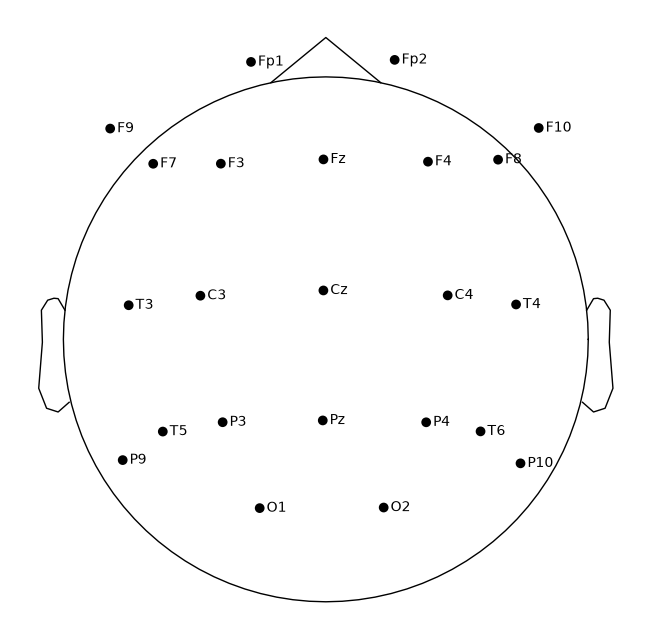

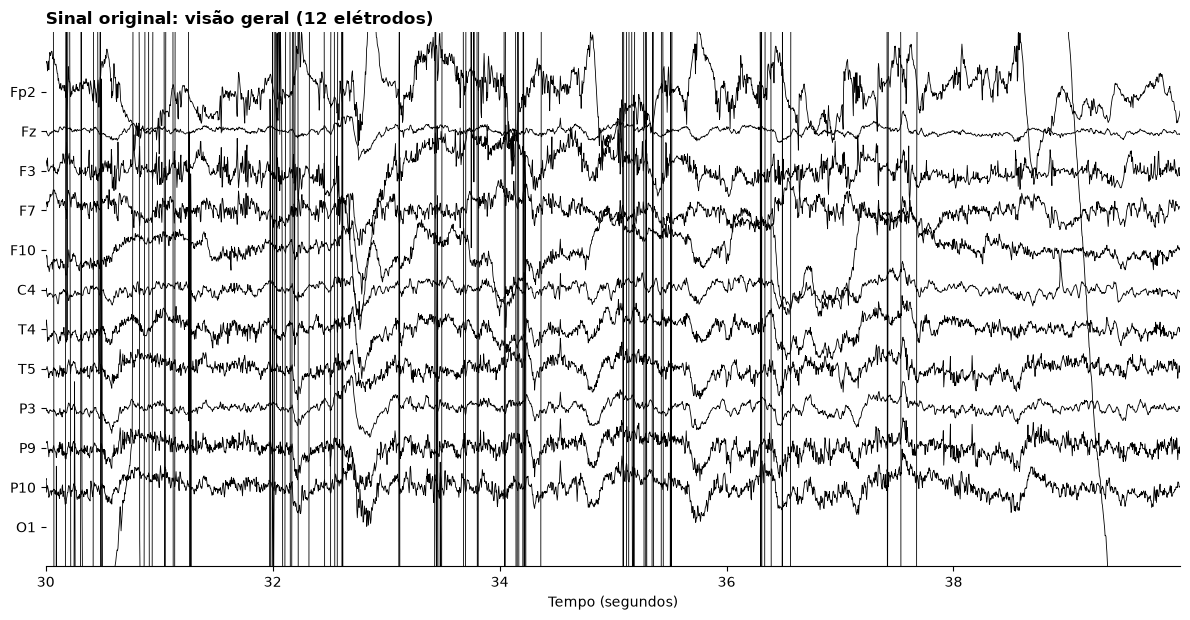

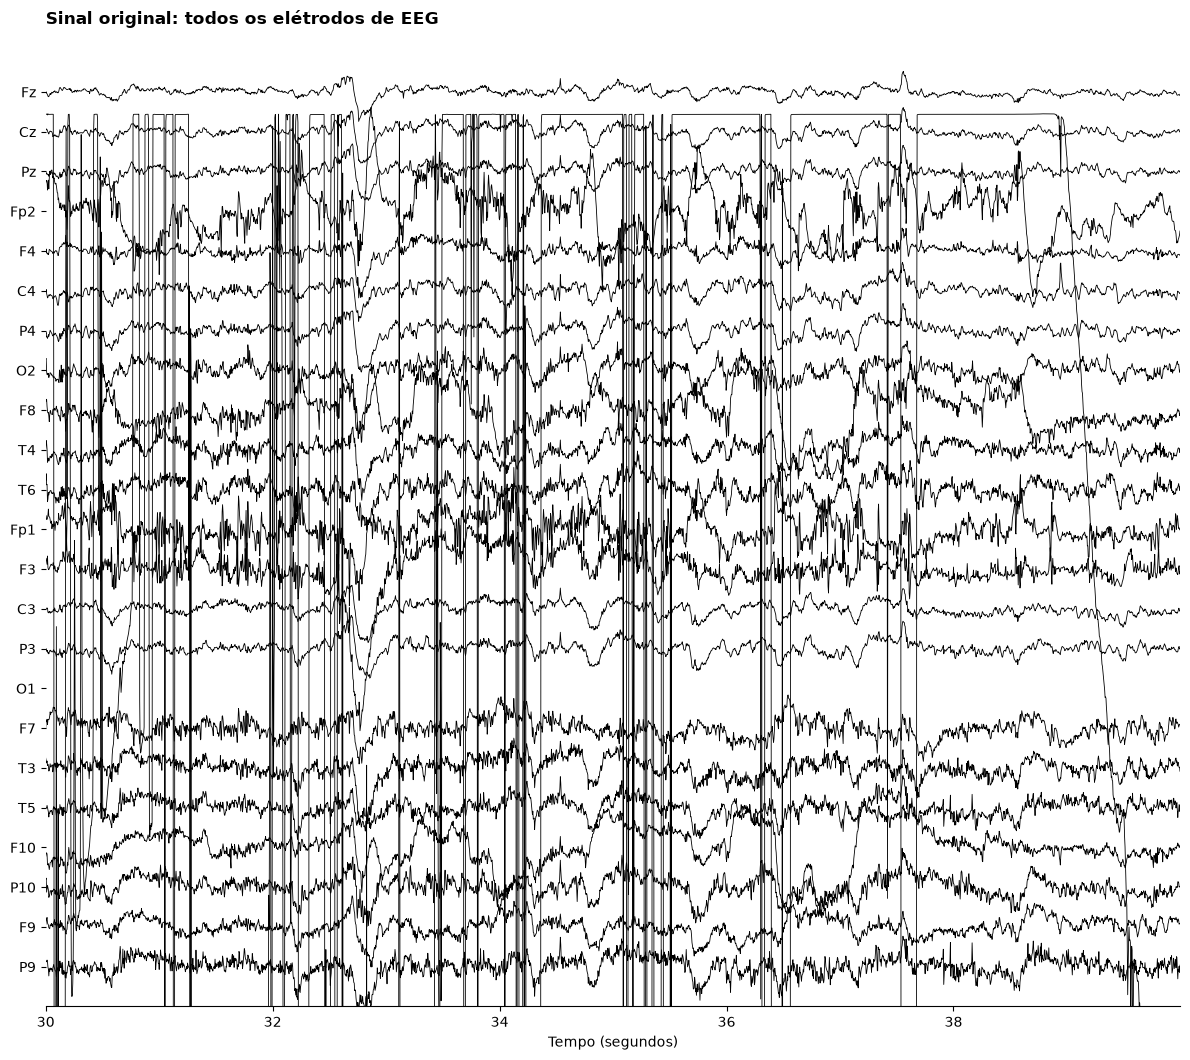

In [43]:
raw, name = load_recording(MY_FILES[0] if MY_FILES else None)
describe(raw, name)

raw.plot_sensors(show_names=True);

# Sinal tal como foi gravado, antes de qualquer filtragem ou correção
show([raw], ["Sinal original: visão geral (12 elétrodos)"])
show([raw], ["Sinal original: todos os elétrodos de EEG"], channels=raw.copy().pick("eeg").ch_names)

**Verificação:** confirme que os elétrodos surgem nas posições corretas. Se o registo incluir canais que não são de EEG (por exemplo, `EOG` ou `ECG`) mas que surgem classificados como EEG, indique o tipo correto neste bloco e execute-o novamente, por exemplo: `raw.set_channel_types({"VEOG": "eog", "ECG": "ecg"})`.

No sinal original, observe a presença de oscilações lentas da linha de base, de ruído rápido e de artefactos de grande amplitude (por exemplo, piscar de olhos nos elétrodos frontais). Estes elementos são tratados nas etapas seguintes e podem ser comparados com o sinal corrigido na etapa 5.

## 2. Interferência da rede elétrica e filtragem

Interferência da rede elétrica: 60 Hz


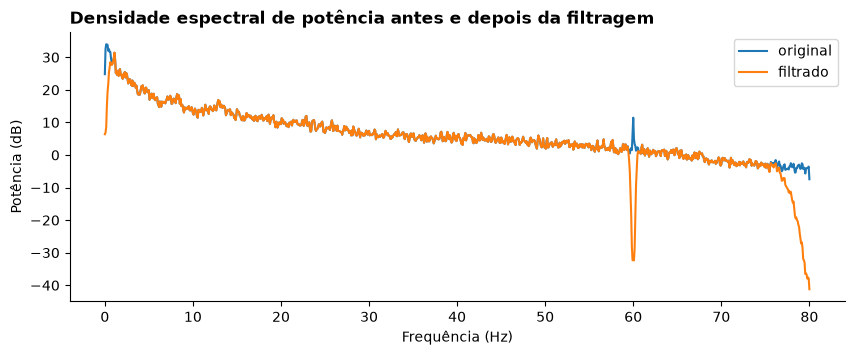

In [24]:
line_freq = detect_line_freq(raw)
filtered = filter_recording(raw, line_freq)

spectrum([raw, filtered], ["original", "filtrado"], "Densidade espectral de potência antes e depois da filtragem")
show([raw, filtered], ["Sinal original", "Sinal filtrado"])

Nesta etapa, o filtro estende-se até aos 100 Hz (ou ao limite permitido pela frequência de amostragem), uma vez que o classificador utilizado na etapa 4 foi treinado nessas condições. O filtro superior escolhido nos parâmetros é aplicado no fim do processamento.

## 3. Elétrodos com mau contacto

In [25]:
bads = find_bad_channels(filtered)

  FT8    critério(s): hf_noise
  T10    critério(s): deviation, hf_noise, correlation, SNR
  T8     critério(s): hf_noise
  TP8    critério(s): hf_noise
4 elétrodo(s) com mau contacto.


Significado dos critérios: **flat**: sinal plano; **deviation**: amplitude muito diferente da dos restantes elétrodos; **hf_noise**: ruído de alta frequência excessivo (frequentemente de origem muscular); **correlation** / **ransac**: baixa concordância com os elétrodos vizinhos; **SNR**: baixa relação sinal-ruído; **dropout**: perdas intermitentes de sinal.

Os elétrodos identificados são interpolados a partir dos elétrodos vizinhos. Em seguida, aplica-se a **referência média**: o potencial de cada elétrodo passa a ser expresso em relação à média de todos os elétrodos.

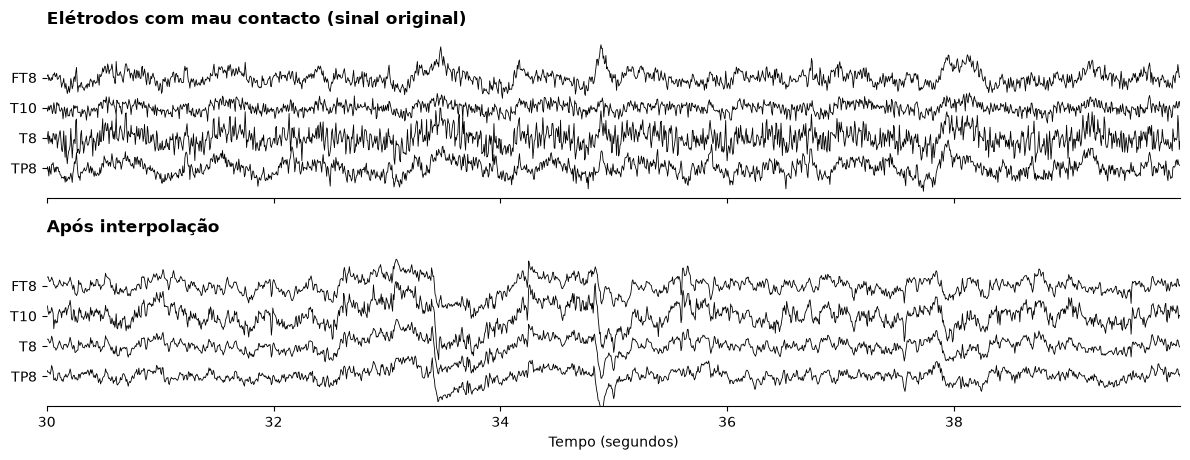

In [26]:
repaired = filtered.copy()
repaired.info["bads"] = bads
repaired.interpolate_bads()
repaired.set_eeg_reference("average")

show([filtered, repaired], ["Elétrodos com mau contacto (sinal original)", "Após interpolação"], channels=bads[:12])

## 4. ICA e classificação automática dos componentes

A ICA decompõe o sinal em componentes independentes. Cada componente é depois classificado pelo **[ICLabel](https://mne.tools/mne-icalabel/)**, um modelo treinado com milhares de componentes classificados por especialistas, nas categorias: cerebral, ocular, muscular, cardíaco, rede elétrica, ruído de elétrodo ou outro.

In [27]:
ica, remove, table = run_ica(repaired)
table

,componente,classificação,probabilidade,excluir
0,ICA000,ocular,0.99,sim
1,ICA001,cerebral,0.96,
2,ICA002,cerebral,0.99,
3,ICA003,ocular,0.74,
4,ICA004,cerebral,0.85,
5,ICA005,cerebral,0.81,
6,ICA006,cerebral,0.83,
7,ICA007,cerebral,0.98,
8,ICA008,outro,0.67,
9,ICA009,outro,0.74,


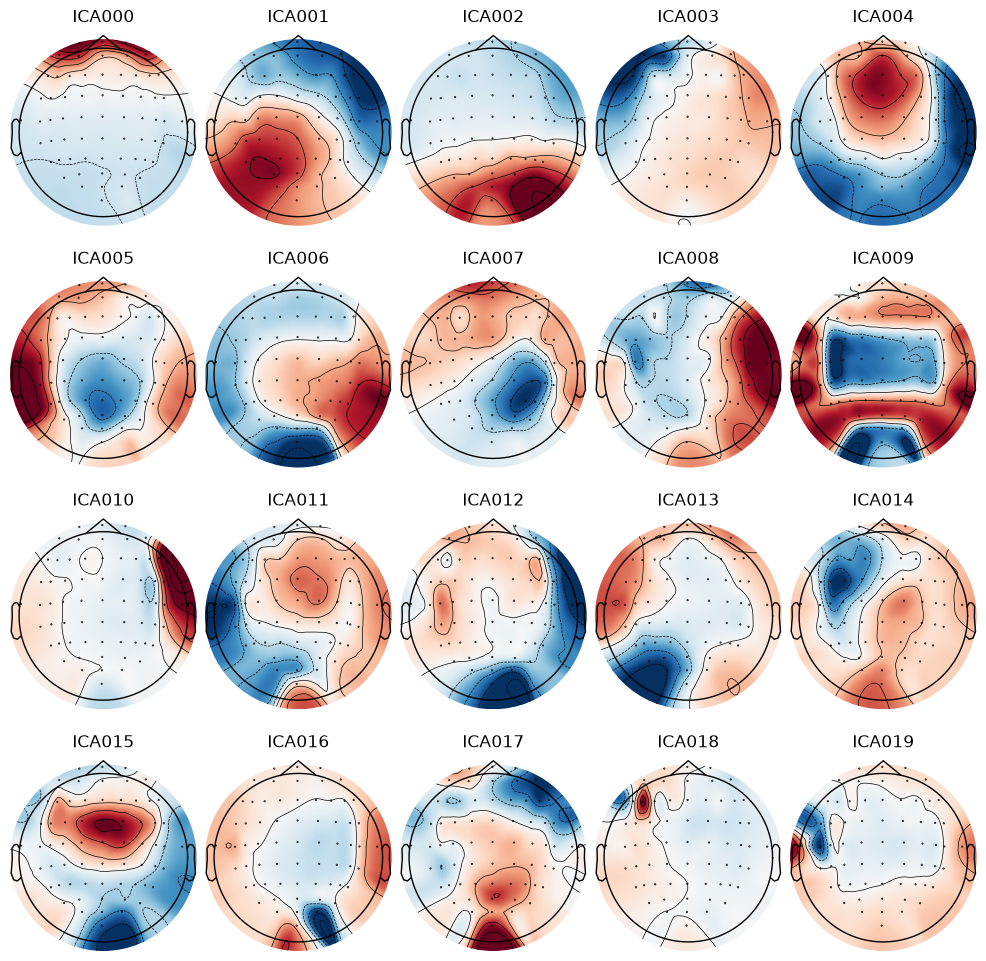

Componentes a excluir: ['ICA000']


In [16]:
ica.plot_components();
print("Componentes a excluir:", [f"ICA{i:03d}" for i in remove] or "nenhum")

**Recomenda-se a verificação da classificação automática.** Em caso de discordância, a seleção pode ser definida manualmente antes de prosseguir, por exemplo `remove = [0, 4]`. Para examinar um componente em detalhe: `ica.plot_properties(repaired, picks=[0])`.

Se persistirem artefactos após a etapa 5 (por exemplo, atividade muscular classificada com uma probabilidade inferior ao limiar), pode reduzir-se o parâmetro **PROBABILIDADE_MINIMA** e executar novamente os blocos a partir dos parâmetros.

## 5. Exclusão dos componentes e comparação

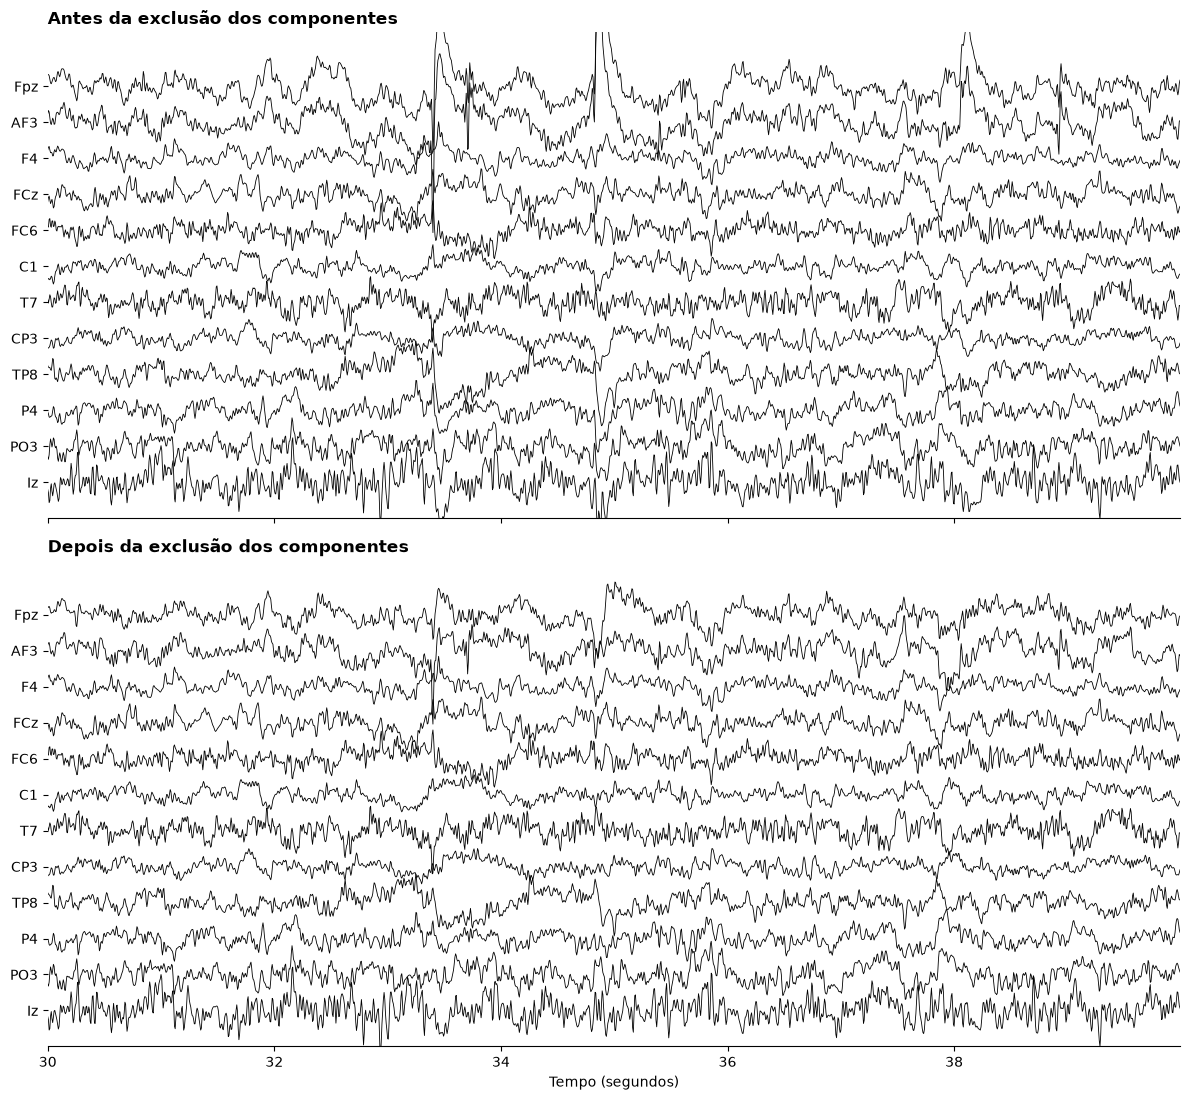

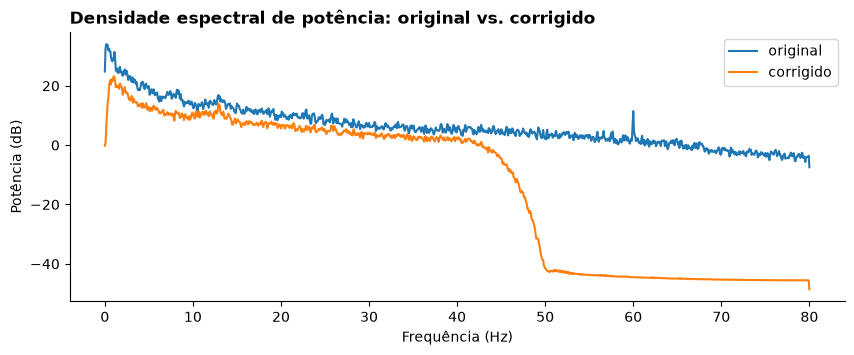

In [17]:
ica.exclude = remove
cleaned = ica.apply(repaired.copy())
cleaned.filter(l_freq=None, h_freq=FILTRO_SUPERIOR_HZ)

# Para uma comparação equivalente, o sinal "antes" recebe o mesmo filtro superior
before = repaired.copy().filter(l_freq=None, h_freq=FILTRO_SUPERIOR_HZ)
show([before, cleaned], ["Antes da exclusão dos componentes", "Depois da exclusão dos componentes"])
spectrum([raw, cleaned], ["original", "corrigido"], "Densidade espectral de potência: original vs. corrigido")

A potência do registo corrigido é globalmente inferior, em resultado da remoção dos artefactos (de grande amplitude) e da utilização da referência média. A atenuação acima do filtro superior corresponde ao filtro final.

## 6. Exportação dos resultados

In [29]:
paths = save_results(name, raw, repaired, cleaned, ica, remove, table, bads, line_freq)
download(paths, f"{name}_resultados.zip")

Resultados guardados em: /Users/anarocha/Projects/eeg-workshop/data/preprocessed/S001R04_resultados.zip


O ficheiro `.zip` é guardado na pasta de transferências do navegador (no Colab) ou na pasta `data/preprocessed/` do projeto (em Jupyter local), e contém:
- **`..._clean-raw.fif`**: o registo corrigido, pronto para análise (pode ser lido com `mne.io.read_raw("...")`);
- **`..._relatorio.html`**: o relatório com todas as figuras e decisões, que pode ser aberto em qualquer navegador;
- **`...-ica.fif`**: a decomposição ICA, que pode ser reutilizada sem necessidade de novo cálculo.

---
# Processamento em lote

Uma vez validados os parâmetros, o bloco seguinte aplica todas as etapas a **todos os registos carregados**, descarrega os resultados num único ficheiro `.zip` e apresenta uma tabela-resumo.

In [30]:
process_all(MY_FILES)

Não foram carregados registos.
